# 17 · Encoders and encoder-decoders: the other two transformer families

Notebooks 00–06 built one kind of transformer, the **decoder-only** model behind GPT, Llama and Qwen. The original transformer (Vaswani et al., 2017) had two halves, and each half became a family of its own:

| family | attention | trained to | famous members | used today for |
|---|---|---|---|---|
| **encoder-only** | bidirectional: every token sees every other | fill in masked tokens | BERT, RoBERTa, DeBERTa, **ModernBERT** | classification, named entities, embeddings, rerankers, safety classifiers |
| **decoder-only** | causal: a token sees only the past | predict the next token | GPT, Llama, Qwen, SmolLM2 | generation, chat, agents, almost every LLM |
| **encoder-decoder** | bidirectional encoder + causal decoder with cross-attention | rebuild corrupted spans, or map input to output | T5, BART, Flan-T5, Whisper | translation, speech recognition, structured rewriting |

This notebook, read after notebook 04, completes the architecture topic:

1. **From scratch:** the same `TransformerLM`, with the causal mask switched off and trained with BERT's masked-language-model objective, shows why seeing both sides of a word matters.
2. **In practice:** classifying real customer-support messages (Banking77, 77 intents) three ways: fine-tuning an encoder (ModernBERT), embeddings + a linear classifier, and asking an LLM. With accuracy, intervals, latency and the number of labelled examples each needs.
3. **Encoder-decoder:** Flan-T5, its cross-attention, and where this design still wins.

**Sources.** Raschka, *Build a Large Language Model (From Scratch)*, ch. 6 (fine-tuning for classification); Alammar and Grootendorst, *Hands-On Large Language Models*, ch. 4 and 11 (text classification, fine-tuning representation models); Stanford CME 295, transformer variants.

## Background: three ways to use one block

### The difference is the mask

All three families stack the same block (attention + feed-forward + residuals + normalization). What changes is **which positions each token may attend to**:

```
encoder (bidirectional)       decoder (causal)             encoder-decoder
  k: t1 t2 t3 t4                k: t1 t2 t3 t4             encoder: bidirectional over the input x
q t1  x  x  x  x              q t1  x  .  .  .             decoder: causal over the output y
  t2  x  x  x  x                t2  x  x  .  .               + cross-attention: every y_j attends
  t3  x  x  x  x                t3  x  x  x  .                 to ALL encoder states of x
  t4  x  x  x  x                t4  x  x  x  x
```

In code (notebook 02's `GroupedQueryAttention`), an encoder is the same layer called with `is_causal=False`. In this repo, that is `ModelConfig(causal=False)`.

### Training an encoder: masked language modelling

A bidirectional model cannot be trained to predict the next token: it would simply look at it. BERT (Devlin et al., 2019) instead hides some tokens and asks the model to recover them:

$$\mathcal{L}_{\text{MLM}} = -\sum_{i \in \mathcal{M}} \log p_\theta\big(x_i \mid x_{\setminus \mathcal{M}}\big)$$

where $\mathcal{M}$ is a random 15 % of the positions. Of those, 80 % are replaced by a `[MASK]` token, 10 % by a random token and 10 % are left unchanged. The mix exists because `[MASK]` never appears when the model is used later: if the model only ever saw `[MASK]` at the positions it is graded on, it would learn nothing useful about the real tokens elsewhere.

Two consequences matter in practice:
- **Sample efficiency.** A causal LM learns from every position of every sequence; MLM only from the 15 % it masks. ELECTRA (Clark et al., 2020) fixed this with *replaced token detection*: a small generator corrupts tokens and the encoder classifies **every** position as original or replaced.
- **No generation.** An encoder gives each position a representation that depends on the whole input. That is ideal for understanding a text, but there is no natural way to write one left to right.

### Why an encoder is the right tool for understanding tasks

For classification, extraction or search, the input is known in full before any decision, so a model that reads it in both directions builds better token representations at the same size. A sentence representation is either the vector of a special first token (`[CLS]`) or the mean of all token vectors, and a small **classification head** (a linear layer) on top of it is fine-tuned together with the encoder (Raschka, ch. 6):

$$p(y \mid x) = \operatorname{softmax}\big(W \, h_{\text{[CLS]}}(x) + b\big)$$

The result is fast (one forward pass, no generation), cheap (a 150M-parameter encoder against a 3B chat model), returns calibrated-ish probabilities over a fixed label set, and never answers outside it. That is why, in 2025, encoders still power most production classifiers, embedding models (sentence-transformers, notebook 10), cross-encoder rerankers and safety filters (Meta's Prompt Guard is a fine-tuned mDeBERTa).

### ModernBERT

BERT-base (2018) stayed the default encoder for six years. **ModernBERT** (Warner et al., 2024) rebuilt it with what decoders had learned in the meantime: RoPE instead of learned positions, GeGLU feed-forward layers, pre-normalization, attention that alternates global layers with 128-token sliding-window layers, *unpadding* (no compute wasted on padding tokens), an 8,192-token context, and pre-training on 2 trillion tokens that include code. We fine-tune `ModernBERT-base` (150M parameters).

### Encoder-decoders

The original transformer and T5 (Raffel et al., 2020) keep both halves. The encoder reads the input once, bidirectionally; the decoder generates the output causally and, in every layer, uses **cross-attention**: its queries come from the output being written, its keys and values from the encoder states of the input,

$$\text{CrossAttn}(Y, X) = \operatorname{softmax}\!\Big(\frac{(Y W_Q)(H_X W_K)^\top}{\sqrt{d_h}}\Big) H_X W_V$$

T5 frames every task as text to text and pre-trains with *span corruption* (spans of the input are replaced by sentinels the decoder must reconstruct). Flan-T5 (Chung et al., 2022) adds instruction tuning.

### Why decoder-only won, and where the others survive

Decoder-only models have one objective that turns all text into training signal, they scale predictably, and they learn new tasks from a prompt (in-context learning) without a task head. For a general assistant that has to generate, they won. But:

- when the task is a **fixed set of labels** and you have some labelled data, a small fine-tuned encoder is usually as accurate, or more, at a tiny fraction of the cost and latency (measured below);
- **embeddings and rerankers** are encoders;
- when input and output are different sequences, as in **translation and speech** (Whisper), encoder-decoders remain competitive. Whether encoder-decoders are better at equal compute is still debated; Google's T5Gemma (2025) revisits it.

**Key papers.** Vaswani et al. (2017), *Attention Is All You Need*; Devlin et al. (2019), *BERT*; Liu et al. (2019), *RoBERTa*; Clark et al. (2020), *ELECTRA*; Raffel et al. (2020), *Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer* (T5); He et al. (2021), *DeBERTa*; Chung et al. (2022), *Scaling Instruction-Finetuned Language Models* (Flan); Warner et al. (2024), *Smarter, Better, Faster, Longer: A Modern Bidirectional Encoder* (ModernBERT); Casanueva et al. (2020), *Efficient Intent Detection with Dual Sentence Encoders* (Banking77).

In [1]:
import os, sys, math, time, tempfile
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # notebooks live in notebooks/<topic>/, so climb up to the repo root
sys.path.insert(0, ROOT)                            # so that `import llm_edu_suite` works from the notebook
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from llm_edu_suite.utils import seed_everything, get_device, count_params, human, show_mask
seed_everything(0)
device = get_device()
print("torch", torch.__version__, "| device", device)

torch 2.14.1+cu130 | device cuda


## 1. From scratch: what bidirectional context buys

We train two models of identical size on the synthetic corpus of notebook 05 (random "words" of 2–4 tokens from a fixed lexicon, separated by token 0) for the same number of steps:

- a **decoder**: `TransformerLM` with causal attention, trained to predict the next token;
- an **encoder**: the same class with `causal=False`, trained with BERT's MLM recipe (15 % of positions, 80/10/10).

Then we hide one token in held-out text and ask both to recover it. The decoder can only use what came before; the encoder uses both sides. The interesting case is the **first token of a word**: from the left, all you know is that a new word starts, so it is a guess among the lexicon's words; from the right, the rest of the word gives it away.

In [2]:
from llm_edu_suite.model import ModelConfig, TransformerLM
from llm_edu_suite.data import synthetic_structured_corpus, train_val_split, get_batch
from llm_edu_suite.training import TrainConfig, train_lm

V = 512; MASK = V                                           # one extra id for [MASK]
data = synthetic_structured_corpus(n_tokens=200_000, vocab=V, n_words=80)
train_data, val_data = train_val_split(data)
SHAPE = dict(vocab_size=V + 1, max_seq_len=64, d_model=128, n_layers=4, n_heads=4, n_kv_heads=4)
STEPS, BATCH, BLOCK = 800, 64, 64

t0 = time.time()
seed_everything(0); decoder = TransformerLM(ModelConfig(**SHAPE))
train_lm(decoder, train_data, val_data, TrainConfig(steps=STEPS, batch_size=BATCH, block_size=BLOCK, max_lr=3e-3, warmup=80,
                                                    eval_every=STEPS, log=False), device)
print(f"decoder trained in {time.time() - t0:.0f}s")

def mask_tokens(x, p=0.15):
    """BERT's recipe: choose 15% of positions; of those, 80% -> [MASK], 10% -> a random token, 10% unchanged."""
    chosen = torch.rand(x.shape, device=x.device) < p
    labels = torch.where(chosen, x, torch.full_like(x, -100))          # the loss only looks at chosen positions
    r = torch.rand(x.shape, device=x.device)
    inp = x.clone()
    inp[chosen & (r < 0.8)] = MASK
    swap = chosen & (r >= 0.8) & (r < 0.9)
    inp[swap] = torch.randint(0, V, (int(swap.sum()),), device=x.device)
    return inp, labels

t0 = time.time()
seed_everything(0); encoder = TransformerLM(ModelConfig(**SHAPE, causal=False)).to(device)
opt = torch.optim.AdamW(encoder.parameters(), lr=3e-3, betas=(0.9, 0.95), weight_decay=0.1)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / 80) * 0.5 * (1 + math.cos(math.pi * min(s, STEPS) / STEPS)))
encoder.train()
for step in range(STEPS):
    x, _ = get_batch(train_data, BLOCK, BATCH, device)
    inp, labels = mask_tokens(x)
    with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
        _, loss = encoder(inp, labels)                       # targets aligned with inputs: predict the token at each masked position
    opt.zero_grad(set_to_none=True); loss.backward(); torch.nn.utils.clip_grad_norm_(encoder.parameters(), 1.0); opt.step(); sched.step()
encoder.eval()
print(f"encoder (MLM) trained in {time.time() - t0:.0f}s | last masked-token loss {loss.item():.3f}")

decoder trained in 30s


encoder (MLM) trained in 28s | last masked-token loss 0.052


In [3]:
@torch.no_grad()
def fill_in_accuracy(n=4000, pos=40, seed=1):
    """Hide the token at `pos` in held-out windows and measure who recovers it, split by its place in a word."""
    g = torch.Generator().manual_seed(seed)
    starts = torch.randint(0, len(val_data) - BLOCK - 1, (n,), generator=g)
    X = torch.stack([val_data[s:s + BLOCK] for s in starts]).to(device)
    target = X[:, pos]
    dec = decoder(X[:, :pos])[0][:, -1].argmax(-1)           # the decoder's guess for `pos` uses tokens 0..pos-1
    Xm = X.clone(); Xm[:, pos] = MASK
    enc_both = encoder(Xm)[0][:, pos].argmax(-1)              # the encoder sees both sides of the hole
    Xl = X[:, :pos + 1].clone(); Xl[:, pos] = MASK
    enc_left = encoder(Xl)[0][:, pos].argmax(-1)             # the same encoder with the right side cut off
    first = (X[:, pos - 1] == 0) & (target != 0)             # the hidden token starts a word
    inside = (X[:, pos - 1] != 0) & (target != 0)
    rows = {}
    for name, pred in (("decoder, left context", dec), ("encoder, left context only", enc_left), ("encoder, both sides", enc_both)):
        ok = (pred == target).float()
        rows[name] = (ok.mean().item(), ok[first].mean().item(), ok[inside].mean().item())
    print(f"{'':28s} {'all':>7s} {'first token of a word':>22s} {'inside a word':>14s}   ({int(first.sum())} / {int(inside.sum())} cases)")
    for name, (a, f_, i_) in rows.items():
        print(f"{name:28s} {a:7.1%} {f_:22.1%} {i_:14.1%}")
    return rows
fill = fill_in_accuracy()

                                 all  first token of a word  inside a word   (989 / 2069 cases)
decoder, left context          73.6%                   2.9%          95.4%
encoder, left context only     73.8%                   2.5%          95.9%
encoder, both sides            99.1%                 100.0%          98.3%


**What the numbers say.** Both models trained for 800 steps (about 30 s each) on the same data. Where the hidden token **starts a word**, the decoder is right 2.9 % of the time: from the left it only knows that a new word begins, so it guesses among the lexicon's 80 words. The encoder that sees both sides recovers it **100 %** of the time, because the rest of the word, to the right of the hole, identifies it. Inside a word, where the left context already pins the token down, all three are at 95–98 %.

The middle row is the control that makes the comparison fair: the *same* encoder with the right side cut off falls back to 2.5 % on first tokens, the decoder's level. The gain comes from the right-hand context, not from the encoder being a better model. That is the whole argument for encoders on understanding tasks, where the full input is available before any decision. Note also that the encoder got there although MLM only grades 15 % of the positions per sequence, against 100 % for the decoder.

## 2. Classifying real messages: encoder, embeddings or LLM?

**The task.** Banking77 (Casanueva et al., 2020; CC BY 4.0) has 13,083 real customer messages to a bank, each labelled with one of **77 intents** ("card_arrival", "lost_or_stolen_card", "exchange_rate"...). Many intents are close cousins ("pending_transfer" vs "transfer_not_received_by_recipient"), which makes it a good test of fine distinctions. We keep the official test set (3,080 messages) untouched, and split 10 % of the training set off as validation for choosing settings.

**Three approaches**, the decision every team building a classifier faces:

| approach | how it works | needs |
|---|---|---|
| fine-tuned encoder | ModernBERT + a linear head, all weights trained on labelled messages | labelled data, a GPU for minutes |
| embeddings + linear classifier | a frozen embedding model turns each message into a vector; logistic regression learns the boundaries | labelled data, no GPU training |
| LLM zero-shot / few-shot | `qwen2.5:3b` picks an intent from the list (structured output, notebook 11), optionally with one example per intent | no labels (zero-shot) or 77 (few-shot) |

In [4]:
import logging, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
import datasets, transformers, huggingface_hub
datasets.disable_progress_bars(); transformers.utils.logging.disable_progress_bar(); transformers.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error(); huggingface_hub.utils.disable_progress_bars()
from datasets import load_dataset
ds = load_dataset("PolyAI/banking77")
LABELS = ds["train"].features["label"].names
split = ds["train"].train_test_split(test_size=0.1, seed=0, stratify_by_column="label")
train_ds, valid_ds, test_ds = split["train"], split["test"], ds["test"]
counts = np.bincount(train_ds["label"], minlength=len(LABELS))
print(f"{len(LABELS)} intents | train {len(train_ds):,} · validation {len(valid_ds):,} · test {len(test_ds):,} | "
      f"examples per intent in train: {counts.min()}-{counts.max()}")
for i in (0, 1, 2):
    print(f"  {LABELS[test_ds[i]['label']]:32s} <- {test_ds[i]['text']}")
y_test = np.array(test_ds["label"])

77 intents | train 9,002 · validation 1,001 · test 3,080 | examples per intent in train: 32-168
  card_arrival                     <- How do I locate my card?
  card_arrival                     <- I still have not received my new card, I ordered over a week ago.
  card_arrival                     <- I ordered a card but it has not arrived. Help please!


### 2.1 Fine-tuning ModernBERT

The standard recipe with Hugging Face: `AutoModelForSequenceClassification` adds a randomly initialised linear head over the pooled representation, and `Trainer` fine-tunes everything with cross-entropy. Best practices that matter here: dynamic padding (`DataCollatorWithPadding`) so each batch is only as long as its longest message, bf16 mixed precision, a learning rate around $5 \times 10^{-5}$ with warm-up and linear decay (the encoder is pretrained; large steps would destroy what it knows), evaluation on validation every epoch, and the test set used once at the end.

To see **how much labelled data** the encoder needs, we train three times: with 8 and 32 examples per intent, and with the full training set (about 117 per intent).

In [5]:
import tempfile
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, PrinterCallback)
from sklearn.metrics import f1_score
import transformers; transformers.logging.set_verbosity_error()

ENC_ID = "answerdotai/ModernBERT-base"
enc_tok = AutoTokenizer.from_pretrained(ENC_ID)
tokenize = lambda b: enc_tok(b["text"], truncation=True, max_length=64)
tok_valid, tok_test = valid_ds.map(tokenize, batched=True), test_ds.map(tokenize, batched=True)
BF16 = device == "cuda" and torch.cuda.is_bf16_supported()

def per_class(dataset, k, seed=0):
    """k examples of every intent: the realistic 'we labelled a few per class' setting."""
    rng = np.random.default_rng(seed); labels = np.array(dataset["label"]); idx = []
    for c in range(len(LABELS)):
        pool = np.where(labels == c)[0]; idx += rng.choice(pool, size=min(k, len(pool)), replace=False).tolist()
    return dataset.select(sorted(idx))

def metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": float((pred == p.label_ids).mean()), "macro_f1": float(f1_score(p.label_ids, pred, average="macro"))}

FT = {}
for name, subset, epochs in (("8 per intent", per_class(train_ds, 8), 20), ("32 per intent", per_class(train_ds, 32), 8),
                             ("all (~117 per intent)", train_ds, 3)):
    model = AutoModelForSequenceClassification.from_pretrained(ENC_ID, num_labels=len(LABELS),
                                                               id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)})
    steps = math.ceil(len(subset) / 32) * epochs
    args = TrainingArguments(output_dir=tempfile.mkdtemp(), num_train_epochs=epochs, per_device_train_batch_size=32,
                             per_device_eval_batch_size=256, learning_rate=5e-5, warmup_steps=int(0.1 * steps), weight_decay=0.01,
                             lr_scheduler_type="linear", bf16=BF16, eval_strategy="epoch", save_strategy="no",
                             logging_strategy="epoch", report_to="none", seed=0, disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=subset.map(tokenize, batched=True), eval_dataset=tok_valid,
                      processing_class=enc_tok, data_collator=DataCollatorWithPadding(enc_tok), compute_metrics=metrics)
    trainer.remove_callback(PrinterCallback)
    t0 = time.time(); trainer.train(); secs = time.time() - t0
    pred = trainer.predict(tok_test).predictions.argmax(-1)
    val = [h["eval_accuracy"] for h in trainer.state.log_history if "eval_accuracy" in h]
    FT[name] = dict(n=len(subset), secs=secs, pred=pred, acc=float((pred == y_test).mean()), f1=float(f1_score(y_test, pred, average="macro")))
    print(f"{name:22s} {len(subset):5d} examples, {epochs:2d} epochs, {secs:4.0f}s | validation acc by epoch {[round(v, 3) for v in val][-3:]} "
          f"| TEST accuracy {FT[name]['acc']:.3f}, macro-F1 {FT[name]['f1']:.3f}")
    if name.startswith("all"):
        best_encoder = trainer.model.eval()
    else:
        del model, trainer
    if device == "cuda": torch.cuda.empty_cache()
print(f"\nModernBERT-base: {sum(p.numel() for p in best_encoder.parameters()) / 1e6:.0f}M parameters, all of them fine-tuned")

8 per intent             616 examples, 20 epochs,  102s | validation acc by epoch [0.679, 0.68, 0.683] | TEST accuracy 0.696, macro-F1 0.693


32 per intent           2464 examples,  8 epochs,  128s | validation acc by epoch [0.862, 0.865, 0.863] | TEST accuracy 0.893, macro-F1 0.893


all (~117 per intent)   9002 examples,  3 epochs,  163s | validation acc by epoch [0.883, 0.919, 0.921] | TEST accuracy 0.930, macro-F1 0.930

ModernBERT-base: 150M parameters, all of them fine-tuned


### 2.2 Frozen embeddings + logistic regression

No encoder training at all: turn each message into a vector with a frozen model and fit a linear classifier (logistic regression, $C$ chosen on validation). We try two frozen representations:

- **`nomic-embed-text`** (the course's embedding model, through Ollama), a model *trained to produce sentence embeddings*, with its `classification:` task prefix;
- **ModernBERT-base without fine-tuning**, mean-pooled over tokens. It is pretrained only with MLM, so its raw vectors were never asked to make similar sentences close.

The comparison tells you what pretraining objective a "general" representation needs.

In [6]:
from transformers import AutoModel
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from llm_edu_suite.config import get_llm, get_embeddings

@torch.no_grad()
def modernbert_mean_pool(texts, bs=256):
    base = AutoModel.from_pretrained(ENC_ID).to(device).eval(); out = []
    for i in range(0, len(texts), bs):
        x = enc_tok(texts[i:i + bs], truncation=True, max_length=64, padding=True, return_tensors="pt").to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=BF16):
            h = base(**x).last_hidden_state.float()
        m = x["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    del base
    return np.concatenate(out)

emb = get_embeddings()
def nomic(texts, bs=64):
    return np.array([v for i in range(0, len(texts), bs) for v in emb.embed_documents([f"classification: {t}" for t in texts[i:i + bs]])])

def fit_linear(Xtr, ytr, Xva, yva):
    best = None
    for C in (0.01, 0.1, 1.0):
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(Xtr, ytr)   # scaled features converge fast
        acc = (clf.predict(Xva) == yva).mean()
        if best is None or acc > best[0]: best = (acc, C, clf)
    return best

LIN = {}
t0 = time.time()
feats = {"ModernBERT frozen, mean-pooled": modernbert_mean_pool}
if device == "cuda": torch.cuda.empty_cache()
feats["nomic-embed-text"] = nomic
y_tr, y_va = np.array(train_ds["label"]), np.array(valid_ds["label"])
for name, fn in feats.items():
    t1 = time.time()
    Xtr, Xva, Xte = fn(train_ds["text"]), fn(valid_ds["text"]), fn(test_ds["text"])
    acc_va, C, clf = fit_linear(Xtr, y_tr, Xva, y_va)
    pred = clf.predict(Xte)
    LIN[name] = dict(pred=pred, acc=float((pred == y_test).mean()), f1=float(f1_score(y_test, pred, average="macro")), C=C, clf=clf, dim=Xtr.shape[1])
    print(f"{name:32s} dim {Xtr.shape[1]:4d} | C={C:<4} validation {acc_va:.3f} | TEST accuracy {LIN[name]['acc']:.3f}, macro-F1 {LIN[name]['f1']:.3f} ({time.time() - t1:.0f}s)")

ModernBERT frozen, mean-pooled   dim  768 | C=0.1  validation 0.882 | TEST accuracy 0.892, macro-F1 0.892 (34s)


nomic-embed-text                 dim  768 | C=0.1  validation 0.925 | TEST accuracy 0.933, macro-F1 0.933 (135s)


### 2.3 Asking an LLM

`qwen2.5:3b` receives the message and must return one of the 77 intents through structured output, with a schema whose only field is a `Literal` of the 77 names. **Zero-shot** gives it only the intent names; **few-shot** adds one real example per intent to the system prompt.

How the structure is enforced matters here (notebook 11). With `method="function_calling"` the model is *asked* to call a tool whose argument must be one of 77 strings, and nothing stops it from not calling the tool or writing a name that is not in the list. With `method="json_schema"`, Ollama turns the schema into a grammar and masks every token that would leave it (**constrained decoding**), so the output is always one of the 77 names. Notebook 11 found function calling the more reliable method on small schemas; a 77-value enum is a different case, so we measure both. LLM calls are slow, so the LLM runs on a stratified sample of 231 test messages (3 per intent); every other method is scored on the same 231 too, which makes the comparison paired.

In [7]:
from typing import Literal
from pydantic import BaseModel
from llm_edu_suite.evaluation import bootstrap_ci, paired_bootstrap_diff
if device == "cuda": torch.cuda.empty_cache()

class Intent(BaseModel):
    intent: Literal[tuple(LABELS)]
llm = get_llm()
ZERO = ("You classify a bank customer's message into exactly one intent. The allowed intents are: "
        + ", ".join(LABELS) + ". Choose the single best intent.")
first_example = {}
for t, l in zip(train_ds["text"], train_ds["label"]):
    first_example.setdefault(l, t)
FEW = ZERO + "\n\nOne example per intent:\n" + "\n".join(f"- \"{first_example[c]}\" -> {LABELS[c]}" for c in range(len(LABELS)))

rng = np.random.default_rng(0)
SUB = np.sort(np.concatenate([rng.choice(np.where(y_test == c)[0], 3, replace=False) for c in range(len(LABELS))]))   # 3 per intent
sub_texts, y_sub = [test_ds[int(i)]["text"] for i in SUB], y_test[SUB]

def run_llm(system, method):
    classifier = llm.with_structured_output(Intent, method=method, include_raw=True)
    preds, fails, times = [], 0, []
    for t in sub_texts:
        t0 = time.time(); out = classifier.invoke([("system", system), ("user", t)]); times.append(time.time() - t0)
        if out["parsed"] is None: fails += 1; preds.append(-1)
        else: preds.append(LABELS.index(out["parsed"].intent))
    return np.array(preds), fails, float(np.median(times))
LLM = {}
for name, system, method in (("LLM zero-shot, function calling", ZERO, "function_calling"),
                             ("LLM zero-shot", ZERO, "json_schema"), ("LLM few-shot (1 per intent)", FEW, "json_schema")):
    t0 = time.time(); pred, fails, lat = run_llm(system, method)
    LLM[name] = dict(pred=pred, acc=float((pred == y_sub).mean()), fails=fails, latency=lat)
    print(f"{name:32s} accuracy on the 231-message sample {LLM[name]['acc']:.3f} | invalid outputs {fails} | median {lat:.2f}s per message ({time.time() - t0:.0f}s)")

LLM zero-shot, function calling  accuracy on the 231-message sample 0.152 | invalid outputs 181 | median 0.31s per message (82s)


LLM zero-shot                    accuracy on the 231-message sample 0.489 | invalid outputs 0 | median 0.25s per message (58s)


LLM few-shot (1 per intent)      accuracy on the 231-message sample 0.619 | invalid outputs 0 | median 0.25s per message (58s)


method                                      labels    accuracy, 231 sample [95% CI]    vs fine-tuned   latency
ModernBERT fine-tuned, all data               9002         0.922 [0.883, 0.957]       +0.000      40 ms
ModernBERT fine-tuned, 32 per intent          2464         0.861 [0.818, 0.905]       -0.061      40 ms
ModernBERT fine-tuned, 8 per intent            616         0.649 [0.589, 0.710]       -0.273      40 ms
nomic embeddings + logistic regression        9002         0.926 [0.892, 0.957]       +0.004      18 ms
ModernBERT frozen + logistic regression       9002         0.896 [0.857, 0.935]       -0.026          -
LLM few-shot (qwen2.5:3b, json_schema)          77         0.619 [0.554, 0.680]       -0.303     249 ms
LLM zero-shot (qwen2.5:3b, json_schema)          0         0.489 [0.424, 0.554]       -0.433     250 ms
LLM zero-shot (function calling)                 0         0.152 [0.104, 0.195]       -0.771     312 ms


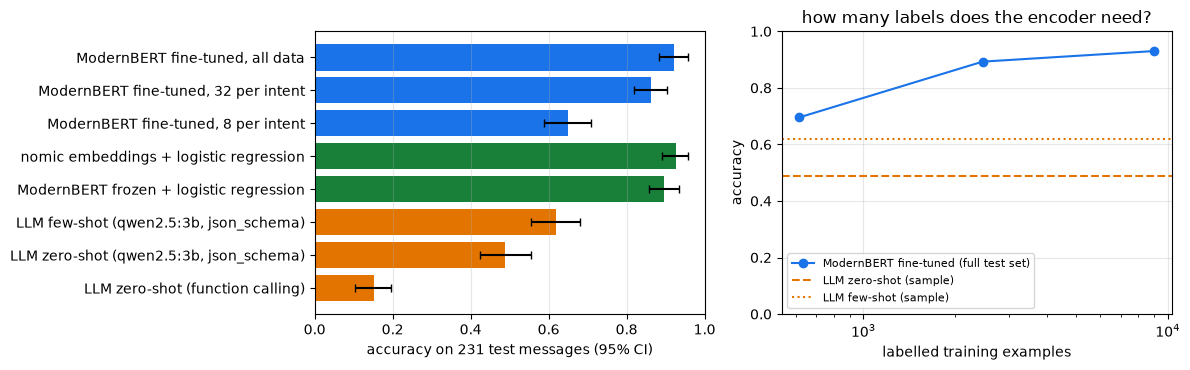

In [8]:
# Latency per message (batch 1), the number that decides the serving cost
@torch.no_grad()
def time_encoder(texts):
    times = []
    for t in texts:
        x = enc_tok(t, return_tensors="pt").to(device)
        if device == "cuda": torch.cuda.synchronize()
        t0 = time.time(); best_encoder(**x).logits.argmax(-1).item(); times.append(time.time() - t0)
    return float(np.median(times[5:]))
def time_nomic(texts):
    clf = LIN["nomic-embed-text"]["clf"]; times = []
    for t in texts:
        t0 = time.time(); clf.predict(np.array([emb.embed_query(f"classification: {t}")])); times.append(time.time() - t0)
    return float(np.median(times[3:]))
lat_enc, lat_nomic = time_encoder(sub_texts[:60]), time_nomic(sub_texts[:30])

rows = [("ModernBERT fine-tuned, all data", FT["all (~117 per intent)"]["pred"][SUB], len(train_ds), "150M (all trained)", lat_enc),
        ("ModernBERT fine-tuned, 32 per intent", FT["32 per intent"]["pred"][SUB], 32 * 77, "150M (all trained)", lat_enc),
        ("ModernBERT fine-tuned, 8 per intent", FT["8 per intent"]["pred"][SUB], 8 * 77, "150M (all trained)", lat_enc),
        ("nomic embeddings + logistic regression", LIN["nomic-embed-text"]["pred"][SUB], len(train_ds), "59k (classifier only)", lat_nomic),
        ("ModernBERT frozen + logistic regression", LIN["ModernBERT frozen, mean-pooled"]["pred"][SUB], len(train_ds), "59k (classifier only)", None),
        ("LLM few-shot (qwen2.5:3b, json_schema)", LLM["LLM few-shot (1 per intent)"]["pred"], 77, "none", LLM["LLM few-shot (1 per intent)"]["latency"]),
        ("LLM zero-shot (qwen2.5:3b, json_schema)", LLM["LLM zero-shot"]["pred"], 0, "none", LLM["LLM zero-shot"]["latency"]),
        ("LLM zero-shot (function calling)", LLM["LLM zero-shot, function calling"]["pred"], 0, "none", LLM["LLM zero-shot, function calling"]["latency"])]
ref = (rows[0][1] == y_sub).astype(float)
print(f"{'method':42s} {'labels':>7s} {'accuracy, 231 sample [95% CI]':>32s} {'vs fine-tuned':>16s} {'latency':>9s}")
SUMMARY = []
for name, pred, n_lab, trained, lat in rows:
    ok = (pred == y_sub).astype(float); m, lo, hi = bootstrap_ci(ok)
    d = paired_bootstrap_diff(ref, ok)
    lat_s = f"{lat * 1000:.0f} ms" if lat is not None else "-"
    print(f"{name:42s} {n_lab:7d} {m:13.3f} [{lo:.3f}, {hi:.3f}]       {d[0]:+.3f}  {lat_s:>9s}")
    SUMMARY.append((name, n_lab, m, lo, hi, lat))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = [r[0] for r in SUMMARY]; accs = [r[2] for r in SUMMARY]
err = np.array([[r[2] - r[3], r[4] - r[2]] for r in SUMMARY]).T
ax[0].barh(names[::-1], accs[::-1], xerr=err[:, ::-1], color=(["#1a73e8"] * 3 + ["#188038"] * 2 + ["#e37400"] * 3)[::-1], capsize=3)
ax[0].set_xlabel("accuracy on 231 test messages (95% CI)"); ax[0].set_xlim(0, 1); ax[0].grid(alpha=.3, axis="x")
ns = [8 * 77, 32 * 77, len(train_ds)]
ax[1].plot(ns, [FT[k]["acc"] for k in ("8 per intent", "32 per intent", "all (~117 per intent)")], "o-", color="#1a73e8", label="ModernBERT fine-tuned (full test set)")
ax[1].axhline(LLM["LLM zero-shot"]["acc"], color="#e37400", ls="--", label="LLM zero-shot (sample)")
ax[1].axhline(LLM["LLM few-shot (1 per intent)"]["acc"], color="#e37400", ls=":", label="LLM few-shot (sample)")
ax[1].set_xscale("log"); ax[1].set_xlabel("labelled training examples"); ax[1].set_ylabel("accuracy"); ax[1].set_ylim(0, 1)
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3); ax[1].set_title("how many labels does the encoder need?")
plt.tight_layout(); plt.show()
del best_encoder
if device == "cuda": torch.cuda.empty_cache()

**What the numbers say.**

- **The fine-tuned encoder is the strongest classifier per label it has seen, and it is data-hungry at first.** With all ~117 examples per intent, ModernBERT reaches **93.0 %** on the full test set (3,080 messages, macro-F1 0.930) after 163 s of training. With 32 per intent it is at 89.3 %; with 8 per intent at 69.6 %, still above the LLM.
- **A good embedding model + logistic regression matches it**: `nomic-embed-text` with a linear classifier reaches **93.3 %** (on the paired 231-message sample: 0.926 against 0.922, a difference well inside the noise) with no neural network training at all, and answers in 18 ms per message. The frozen ModernBERT, never trained for similarity, still gets 89.2 % with the same classifier: a linear probe with 9,000 labels can carve good boundaries even in raw MLM features, though four points behind a model built for embeddings.
- **The LLM is far behind on a 77-way task.** With constrained decoding, `qwen2.5:3b` gets **48.9 %** zero-shot and **61.9 %** with one example per intent, while every labelled approach is above 86 %. Many intents are near-duplicates that only data teaches ("pending_transfer" vs "transfer_not_received_by_recipient"), and a 3B model with a 77-name list in its prompt cannot learn those boundaries from a description.
- **How the output is constrained decided between usable and useless.** With `function_calling` the same model returned no valid intent for 181 of 231 messages (most of the time it simply did not call the tool), for 15.2 % accuracy. Grammar-constrained decoding (`json_schema`) made every output valid. Notebook 11 found function calling more reliable on a small schema; a large enum is the case where constrained decoding is the right tool.

The learning curve on the right is the business answer: **once you have labelled a few dozen examples per class, a small encoder wins**, and it keeps improving with data while prompting does not.

## 3. Encoder-decoder: Flan-T5 and cross-attention

`google/flan-t5-small` (77M parameters) is a T5 with instruction tuning. The encoder reads the instruction and input once; the decoder writes the answer token by token, and every decoder layer attends to the encoder's output through cross-attention. Below we translate a support message and look at the cross-attention of the last decoder layer: each row is a token the decoder wrote, each column a token of the input, and a bright cell means "while writing this, I was reading that".

Flan-T5-small: 77M parameters | encoder stack 19M, decoder stack 25M (incl. cross-attention), shared embedding 16M
one decoder block = T5LayerSelfAttention -> T5LayerCrossAttention -> T5LayerFF | one encoder block = T5LayerSelfAttention -> T5LayerFF



Translate English to German: My card was charged twice for the same purchase.
-> Meine Kreditkarte hat zweifach für die gleichen Einzahlung.


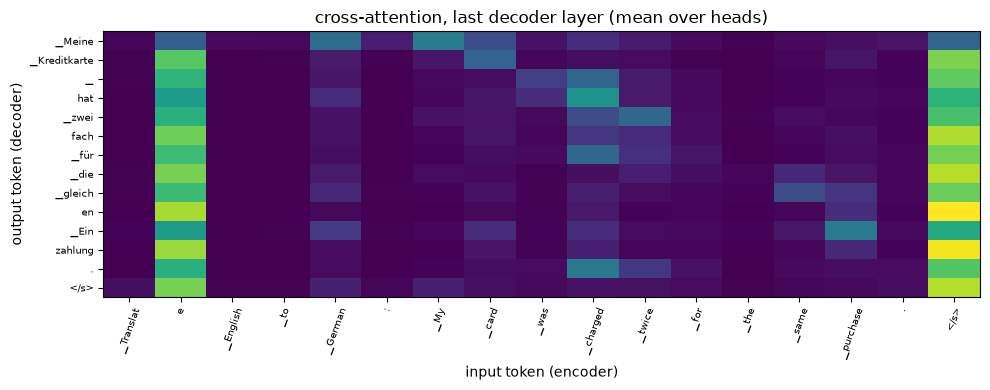


Is this message about a lost card or a transfer? Message: I can't find my card anywhere, I think it was stolen.
-> lost card



Summarize in one sentence: The customer ordered a new card two weeks ago, it has not arrived, and they need it before a trip next Monday.
-> The customer has not received the card they need before a trip.


In [9]:
from transformers import AutoModelForSeq2SeqLM
T5_ID = "google/flan-t5-small"
t5_tok = AutoTokenizer.from_pretrained(T5_ID)
t5 = AutoModelForSeq2SeqLM.from_pretrained(T5_ID, attn_implementation="eager").to(device).eval()   # eager: the fused SDPA kernel does not return attention weights
n_enc = sum(p.numel() for p in t5.encoder.parameters()); n_all = sum(p.numel() for p in t5.parameters())
n_shared = t5.shared.weight.numel()
print(f"Flan-T5-small: {n_all / 1e6:.0f}M parameters | encoder stack {(n_enc - n_shared) / 1e6:.0f}M, decoder stack "
      f"{(n_all - n_enc - t5.lm_head.weight.numel()) / 1e6:.0f}M (incl. cross-attention), shared embedding {n_shared / 1e6:.0f}M")
print("one decoder block =", " -> ".join(type(l).__name__ for l in t5.decoder.block[0].layer), "| one encoder block =",
      " -> ".join(type(l).__name__ for l in t5.encoder.block[0].layer))

src = "Translate English to German: My card was charged twice for the same purchase."
x = t5_tok(src, return_tensors="pt").to(device)
with torch.no_grad():
    out = t5.generate(**x, max_new_tokens=32)
    fw = t5(**x, decoder_input_ids=out[:, :-1], output_attentions=True)
print("\n" + src + "\n->", t5_tok.decode(out[0], skip_special_tokens=True))
cross = fw.cross_attentions[-1][0].mean(0).float().cpu().numpy()          # last decoder layer, averaged over heads: (T_out, T_in)
in_toks = t5_tok.convert_ids_to_tokens(x["input_ids"][0]); out_toks = t5_tok.convert_ids_to_tokens(out[0, 1:])
fig, ax = plt.subplots(figsize=(10, 4))
ax.imshow(cross, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(in_toks))); ax.set_xticklabels(in_toks, rotation=70, fontsize=7)
ax.set_yticks(range(len(out_toks))); ax.set_yticklabels(out_toks, fontsize=7)
ax.set_xlabel("input token (encoder)"); ax.set_ylabel("output token (decoder)"); ax.set_title("cross-attention, last decoder layer (mean over heads)")
plt.tight_layout(); plt.show()
for prompt in ["Is this message about a lost card or a transfer? Message: I can't find my card anywhere, I think it was stolen.",
               "Summarize in one sentence: The customer ordered a new card two weeks ago, it has not arrived, and they need it before a trip next Monday."]:
    with torch.no_grad():
        ans = t5_tok.decode(t5.generate(**t5_tok(prompt, return_tensors="pt").to(device), max_new_tokens=40)[0], skip_special_tokens=True)
    print(f"\n{prompt}\n-> {ans}")

**What the numbers say.** Flan-T5-small's 77M parameters split into a 19M encoder stack, a 25M decoder stack (larger, because each decoder block adds a cross-attention layer between self-attention and the feed-forward) and a 16M shared embedding. It classifies the stolen-card message correctly ("lost card") and writes a reasonable one-sentence summary, but its translation is wrong: "Einzahlung" means *deposit*, not *purchase*, and the sentence is not grammatical German. At 77M parameters that is expected; the point here is the mechanism.

The cross-attention map shows it. Two input columns light up for every output token: the "e" of "Translate" and the end-of-sequence token `</s>`. These are *attention sinks*: positions a layer parks probability mass on when it has nothing specific to read, a known pattern in trained transformers (notebook 03). Beneath them there is a faint alignment: "Kreditkarte" reads "card", "zwei"/"fach" read "charged" and "twice", "Einzahlung" reads "purchase". The last layer of a small model is a noisy place to look at alignment; earlier layers and larger models show it much more cleanly.

## Results

| experiment | measured | what it shows |
|---|---|---|
| hidden token at the start of a word (from scratch, same size and steps) | decoder 2.9 % · encoder with both sides **100 %** · same encoder, left side only 2.5 % | bidirectional context is the encoder's advantage, and it comes from the right-hand side |
| Banking77, ModernBERT fine-tuned, 8 / 32 / ~117 examples per intent | 69.6 % / 89.3 % / **93.0 %** test accuracy (3,080 messages) | a fine-tuned encoder is accurate and keeps improving with labels |
| Banking77, frozen embeddings + logistic regression | nomic-embed **93.3 %** · ModernBERT frozen 89.2 % | with labels, a sentence-embedding model + a linear classifier matches fine-tuning at a fraction of the effort |
| Banking77, `qwen2.5:3b` (231-message sample) | zero-shot 48.9 % · few-shot 61.9 % · function calling 15.2 % (181 invalid outputs) | prompting a small LLM is the weakest option for a large label set; constrained decoding is required for large enums |
| latency per message, batch 1 | embeddings + classifier 18 ms · encoder 40 ms · LLM ~250 ms | an encoder or a linear classifier is also the cheapest to serve |
| Flan-T5-small (77M) | 19M encoder + 25M decoder (with cross-attention) + 16M shared embedding; translation wrong, classification and summary reasonable | how an encoder-decoder is organised, and what cross-attention reads |

## In production

**Choosing a text classifier.** The measurements above match what teams find in practice:

1. **No labels yet, or labels that change weekly:** prompt an LLM, with constrained decoding (`json_schema` / grammar) so the output is always a valid label, and a few examples per class. Log its predictions: they are your first training set.
2. **A few hundred labelled examples or more:** start with **embeddings + logistic regression**. It trains in seconds on a CPU, is trivial to retrain and to explain, and served 93 % here. Use the embedding model's task prefix (`classification:` for nomic).
3. **Need the last points, or the label boundaries are subtle:** **fine-tune an encoder** (ModernBERT, DeBERTa-v3) with `AutoModelForSequenceClassification` + `Trainer`: learning rate around $5 \times 10^{-5}$, warm-up, a few epochs, early stopping on a validation split, dynamic padding, bf16.

**Settings that matter.** Keep a stratified validation split and touch the test set once. Report macro-F1 as well as accuracy when classes are imbalanced. For a large label set, look at the confusion matrix: errors cluster in near-duplicate classes, and merging or redefining them often helps more than a bigger model.

**What to monitor.** Prediction confidence, since a drop in average max-probability signals drift. The share of each predicted class against its historical rate. A sample of low-confidence predictions sent to human review, which become new training data. Retrain when the label set changes.

**Failure modes.** Silent label drift (new kinds of requests forced into old classes; add an "other" class or a confidence threshold). An LLM classifier that answers outside the label set (prevent it with constrained decoding, as measured above). Over-confident fine-tuned models on out-of-distribution text (calibrate with temperature scaling on validation). Leakage when near-duplicate messages land in both train and test.

**Encoder-decoders today.** Use them where input and output are different sequences and quality per parameter matters: speech recognition (Whisper), translation (NLLB, MADLAD), and some structured rewriting. For general generation and chat, decoder-only models are the default.

**Next:** back to the main path with `05_pretraining.ipynb`, or notebook 10 to see encoders at work as embedding models in RAG.